<a href="https://colab.research.google.com/github/Digitalbuilder2026/Intro-to-Computer-Vision/blob/main/Word2Vec.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
# ===== CELL 1: INSTALL THE LIBRARIES =====
# SUMMARY: Install (or upgrade to) recent versions of the four libraries this lab uses.
#   gensim       -> contains Word2Vec and the text8 downloader
#   scikit-learn -> PCA (flattening 100-D to 2-D) and cosine similarity
#   matplotlib   -> drawing plots
#   seaborn      -> the colored heatmap
# If Colab asks you to RESTART the session after this cell, do it, then run from the top.

# %pip installs into the Python environment used by this notebook.
# No SciPy downgrade is requested: current Gensim supports current SciPy releases.
%pip -q install -U "gensim>=4.3" "scikit-learn>=1.3" "matplotlib>=3.7" "seaborn>=0.13"
# %pip   = notebook "magic" command (not Python) that runs pip inside this notebook's Python
# -q     = quiet: fewer progress messages
# -U     = upgrade if an older version is already installed
# ">=4.3" = "version 4.3 or newer"; the quotes stop ">" from being read as a file redirect

In [ ]:
# ===== CELL 2: IMPORTS AND REPRODUCIBILITY =====
# SUMMARY: Bring every tool into the notebook once, at the top, and fix the random seed
# so your "random" results match everyone else's.

from pathlib import Path        # builds file paths that work on any operating system
import time                     # a stopwatch: we time the download and the training

import gensim.downloader as api                 # Gensim's downloader: fetches the text8 TEXT (not a finished model)
import matplotlib.pyplot as plt                 # plotting; "plt" is the standard nickname
import numpy as np                              # grids of numbers; every word vector is a NumPy array
import seaborn as sns                           # makes the colored heatmap
from gensim.models import Word2Vec              # the Word2Vec learner itself
from gensim.models.word2vec import Text8Corpus  # FIX: reads the text8 file directly (avoids the smart_open crash)
from sklearn.decomposition import PCA           # Principal Component Analysis: squashes 100-D down to 2-D
from sklearn.metrics.pairwise import cosine_similarity  # "how much do two vectors point the same way?"

SEED = 42                          # one seed number used everywhere (any number works; 42 is tradition)
np.random.seed(SEED)               # make NumPy's "random" choices repeatable
plt.rcParams["figure.dpi"] = 120   # rc = Matplotlib settings; dpi = dots per inch, so plots look sharper

print("Imports succeeded. We will train Word2Vec from text8 in this notebook.")  # confirmation message

Imports succeeded. We will train Word2Vec from text8 in this notebook.


In [ ]:
# ===== CELL 3: A TINY PRACTICE RUN =====
# SUMMARY: Train Word2Vec on three made-up sentences just to see the input format and the
# output. Twelve words can't teach meaning; this only proves the code works.

# Each inner list is a short token sequence. This is only an API warm-up.
tiny_sentences = [                               # a LIST OF LISTS: one inner list per sentence
    ["small", "cat", "chases", "mouse"],         # each sentence is already split into words ("tokens")
    ["small", "dog", "chases", "ball"],
    ["cat", "and", "dog", "play"],
]

tiny_model = Word2Vec(
    sentences=tiny_sentences,   # the training text
    vector_size=10,             # each word's address has 10 numbers (the real run uses 100)
    window=2,                   # look 2 words left and right for context
    min_count=1,                # keep words that appear even once (default 5 would drop everything here)
    sg=1,                       # 1 = skip-gram, 0 = CBOW (the default)
    negative=2,                 # 2 random "noise" words per real word pair
    workers=1,                  # use 1 CPU thread
    seed=SEED,                  # repeatable random starting addresses
    epochs=20,                  # 20 full passes through the text
)
print("Tiny-model vocabulary:", tiny_model.wv.index_to_key)          # .wv = "word vectors"; index_to_key = vocabulary, most frequent first
print("One tiny-model vector has shape:", tiny_model.wv["cat"].shape) # look up cat's vector; .shape = how many numbers
print("This confirms the API only; it is not a semantic demonstration.")

Tiny-model vocabulary: ['dog', 'chases', 'cat', 'small', 'play', 'and', 'ball', 'mouse']
One tiny-model vector has shape: (10,)
This confirms the API only; it is not a semantic demonstration.


In [ ]:
?Word2Vec

In [ ]:
# ===== CELL 4: THE CONTROL PANEL =====
# SUMMARY: Every setting for the real experiment lives here, in CAPITAL letters
# (Python's way of saying "this is a setting"). Change things HERE, nowhere else.

# ------------------------ USER-EDITABLE SETTINGS ------------------------
MAX_TOKENS = 2_000_000  # Practical cap. Use None for all text8 tokens.   (underscores just make 2,000,000 readable)
EPOCHS = 5              # More passes take longer; this value is safe to edit.

QUERY_WORD = "king"     # Nearest-neighbor lookup after training.
COMPARE_WORD = "queen"  # Explicit cosine similarity with QUERY_WORD.
WORDS = [               # the words we'll plot: three "teams"
    "cat", "dog", "horse", "lion", "tiger",       # animals
    "car", "train", "bus", "bicycle",               # transport
    "apple", "banana", "orange", "grape",           # fruit
]

# An optional analogy probe: B - A + C. It may fail or be uninformative.
ANALOGY_A = "man"       # the word we SUBTRACT
ANALOGY_B = "king"      # the starting word
ANALOGY_C = "woman"     # the word we ADD
TOPN = 10               # how many neighbors to list

# -------------------- REQUESTED WORD2VEC CORE SETTINGS -------------------
VECTOR_SIZE = 100       # 100 numbers per word
WINDOW = 5              # 5 words of context on each side
MIN_COUNT = 5           # drop words seen fewer than 5 times
SG = 1          # 1 = skip-gram; change to 0 only for a CBOW comparison.
NEGATIVE = 5            # 5 noise words per real pair
WORKERS = 1     # One worker reduces scheduling-related run-to-run variation.

OUTPUT_DIR = Path("word2vec_outputs")                 # folder for the two plots
MODEL_PATH = Path("word2vec_text8_skipgram.model")    # file name for the saved model
OUTPUT_DIR.mkdir(exist_ok=True)                       # create the folder; don't crash if it already exists

print(f"Configured for up to {MAX_TOKENS if MAX_TOKENS is not None else 'all'} text8 tokens and {EPOCHS} epochs.")

Configured for up to 2000000 text8 tokens and 5 epochs.


In [ ]:
# ===== CELL 5: DOWNLOAD text8 AND KEEP THE FIRST 2,000,000 WORDS =====
# SUMMARY: Download the text8 corpus (first run only), walk through it chunk by chunk,
# and fill a list until we've kept exactly MAX_TOKENS words. Word2Vec needs the text
# held in memory because it re-reads it once per epoch.

def collect_text8_subset(max_tokens):
    """Return restartable lower-case text8 chunks and the number of retained tokens."""
    if max_tokens is not None and max_tokens <= 0:          # guard: a zero or negative cap makes no sense
        raise ValueError("MAX_TOKENS must be positive, or None for the full dataset.")

    sentences = []      # our "cart": a list of word lists
    kept_tokens = 0     # running count of words kept so far

    # Gensim downloads text8 on the first call, then reuses its local cache.
    # return_path=True gives the downloaded file's path and skips Gensim's
    # text8 loader script, which breaks with smart_open 7+ (current Colab).
    text8_path = api.load("text8", return_path=True)   # download if needed; return the FILE PATH, not the data
    for raw_chunk in Text8Corpus(text8_path):          # read the file as chunks of up to 10,000 words each
        # text8 is already lower case; repeating lower() documents our tokenizer.
        tokens = [token.lower() for token in raw_chunk]   # list comprehension: lowercase every word in the chunk

        if max_tokens is not None:
            remaining = max_tokens - kept_tokens          # how many more words we still need
            if remaining <= 0:                            # (safety check; the break at the bottom always fires first)
                break
            tokens = tokens[:remaining]                   # slice: keep only as many words as we still need

        if tokens:                                        # skip empty chunks
            sentences.append(tokens)                      # add this chunk to the cart
            kept_tokens += len(tokens)                    # update the running count

        if max_tokens is not None and kept_tokens >= max_tokens:
            break                                         # cart is full: stop reading

    if not sentences:                                     # nothing collected? fail loudly with a helpful message
        raise RuntimeError("No tokens were collected. Check internet access and MAX_TOKENS.")
    return sentences, kept_tokens                         # hand back the cart and the word count

load_started = time.perf_counter()                        # start the stopwatch
sentences, token_count = collect_text8_subset(MAX_TOKENS) # run the function; catch both return values
print(f"Collected {token_count:,} lower-case tokens in {len(sentences):,} chunks.")   # :, adds thousands commas
print(f"Download/preparation time: {time.perf_counter() - load_started:.1f} seconds") # :.1f = one decimal place
print("First 20 tokens:", sentences[0][:20])              # peek at the first 20 words of the first chunk

[==================================================] 100.0% 31.6/31.6MB downloaded
Collected 2,000,000 lower-case tokens in 200 chunks.
Download/preparation time: 3.8 seconds
First 20 tokens: ['anarchism', 'originated', 'as', 'a', 'term', 'of', 'abuse', 'first', 'used', 'against', 'early', 'working', 'class', 'radicals', 'including', 'the', 'diggers', 'of', 'the', 'english']


In [ ]:
# ===== CELL 6: TRAIN THE REAL MODEL =====
# SUMMARY: One call builds the vocabulary (dropping words seen fewer than 5 times) and then
# trains skip-gram for 5 epochs over our 2,000,000 words. Then we report time, vocabulary
# size, and vector size.

train_started = time.perf_counter()   # start the stopwatch

# The constructor builds the vocabulary and trains for EPOCHS passes because
# sentences is supplied directly. Each learned vector has VECTOR_SIZE = 100.
model = Word2Vec(
    sentences=sentences,        # our 2,000,000 real text8 words
    vector_size=VECTOR_SIZE,    # 100 numbers per word
    window=WINDOW,              # 5 words of context each side
    min_count=MIN_COUNT,        # ignore words seen fewer than 5 times
    sg=SG,                      # 1 = skip-gram
    negative=NEGATIVE,          # 5 noise words per real pair
    workers=WORKERS,            # 1 CPU thread (more repeatable)
    seed=SEED,                  # repeatable starting addresses
    epochs=EPOCHS,              # 5 full passes
)

train_seconds = time.perf_counter() - train_started                       # elapsed seconds
print(f"Training finished in {train_seconds / 60:.2f} minutes.")           # convert to minutes, 2 decimals
print(f"Vocabulary after min_count={MIN_COUNT}: {len(model.wv):,} words")   # how many words got an address
print("Vector shape for an available word:", model.wv[model.wv.index_to_key[0]].shape)  # vector of the #1 most frequent word

Training finished in 0.97 minutes.
Vocabulary after min_count=5: 21,681 words
Vector shape for an available word: (100,)


In [ ]:
# ===== CELL 7: SAVE A CHECKPOINT (AND OPTIONALLY KEEP TRAINING) =====
# SUMMARY: Save the whole model to a file, load it right back to prove the save worked,
# and (only if you flip a switch) train for extra epochs.

# Save and reload the complete model. The file appears in Colab's working directory.
model.save(str(MODEL_PATH))                 # write the WHOLE model (including what's needed to keep training)
model = Word2Vec.load(str(MODEL_PATH))      # read it straight back: proves the save actually works
print(f"Checkpoint saved and reloaded: {MODEL_PATH.resolve()}")   # .resolve() = the full path on disk

# Leave False for the standard lab. Change only after understanding that it
# changes the checkpoint's vectors by making additional passes over the data.
RESUME_TRAINING = False     # the switch: False = do nothing extra
MORE_EPOCHS = 1             # how many extra passes if the switch is on

if RESUME_TRAINING:
    model.train(sentences, total_examples=len(sentences), epochs=MORE_EPOCHS)  # extra passes; total_examples = how many sentences to expect
    model.save(str(MODEL_PATH))                                                # save the improved model
    print(f"Resumed training for {MORE_EPOCHS} additional epoch(s) and saved again.")
else:
    print("Resume is off; the standard checkpoint is unchanged.")

Checkpoint saved and reloaded: /content/word2vec_text8_skipgram.model
Resume is off; the standard checkpoint is unchanged.


In [ ]:
# ===== CELL 8: NEAREST NEIGHBORS AND ONE COSINE SCORE =====
# SUMMARY: Safely look up QUERY_WORD's 10 nearest neighbors, then measure the cosine
# similarity between QUERY_WORD and COMPARE_WORD. Missing words get a friendly message
# instead of a crash.

def normalize_and_check(word):
    """Lowercase a user word and report whether training retained it."""
    normalized = word.lower().strip()                 # "King " -> "king"
    if normalized not in model.wv.key_to_index:       # key_to_index = dictionary of every word with an address
        print(f"'{word}' → '{normalized}' is out of vocabulary (OOV).")
        return None                                   # None = "nothing"; lets the caller skip safely
    return normalized

query = normalize_and_check(QUERY_WORD)       # "king" (or None)
compare = normalize_and_check(COMPARE_WORD)   # "queen" (or None)

if query is not None:
    print(f"\nTop {TOPN} cosine neighbors for '{query}':")
    for neighbor, score in model.wv.most_similar(query, topn=TOPN):   # ranks ALL words by cosine to "king"
        print(f"  {neighbor:>15s}  {score: .3f}")                     # >15s = right-align in 15 spaces; .3f = 3 decimals

if query is not None and compare is not None:
    # Reshape each 100-number vector into one row for sklearn's pairwise API.
    score = cosine_similarity(
        model.wv[query].reshape(1, -1),       # turn the 100-number list into a 1-row table (-1 = "you work out the size")
        model.wv[compare].reshape(1, -1),
    )[0, 0]                                   # result is a 1x1 table; [0, 0] pulls out the single number
    print(f"\nCosine similarity('{query}', '{compare}') = {score:.3f}")
else:
    print("\nChoose in-vocabulary words to calculate this cosine score.")


Top 10 cosine neighbors for 'king':
          macedon   0.810
               iv   0.804
           aragon   0.798
         portugal   0.792
          castile   0.787
             viii   0.787
           epirus   0.786
           prince   0.784
           afonso   0.777
              vii   0.776

Cosine similarity('king', 'queen') = 0.769


In [ ]:
# ===== CELL 9: THE ANALOGY PROBE (king - man + woman) =====
# SUMMARY: Start at "king," subtract "man," add "woman," and list the 5 words closest to
# where we land. A probe of what this corpus taught the model, not a fact checker.

analogy_words = [
    normalize_and_check(ANALOGY_A),   # "man"
    normalize_and_check(ANALOGY_B),   # "king"
    normalize_and_check(ANALOGY_C),   # "woman"
]

if all(analogy_words):                # True only if NONE of the three is None (all in vocabulary)
    a, b, c = analogy_words           # unpacking: three items into three names
    print(f"Analogy probe: {b} - {a} + {c}")
    for word, score in model.wv.most_similar(positive=[b, c], negative=[a], topn=5):  # add b and c, subtract a
        print(f"  {word:>15s}  {score: .3f}")
else:
    print("Analogy skipped because at least one requested word is OOV.")

Analogy probe: king - man + woman
          macedon   0.718
         portugal   0.699
         daughter   0.699
          castile   0.686
               iv   0.683


In [ ]:
# ===== BONUS CELL A (not in the original notebook): DON'T HIDE THE INPUT WORDS =====
# SUMMARY: Do the king - man + woman arithmetic ourselves and search ALL words,
# including the three we typed, to see what really sits closest.

target = (model.wv.get_vector("king", norm=True)     # norm=True: use the length-1 version of each vector
          - model.wv.get_vector("man", norm=True)    # subtract "man"
          + model.wv.get_vector("woman", norm=True)) # add "woman"
print(model.wv.similar_by_vector(target, topn=3))    # nearest words to that point, with nothing hidden

[('king', 0.864128053188324), ('macedon', 0.7179728150367737), ('portugal', 0.6993967294692993)]


OOV words omitted from both plots: ['grape']


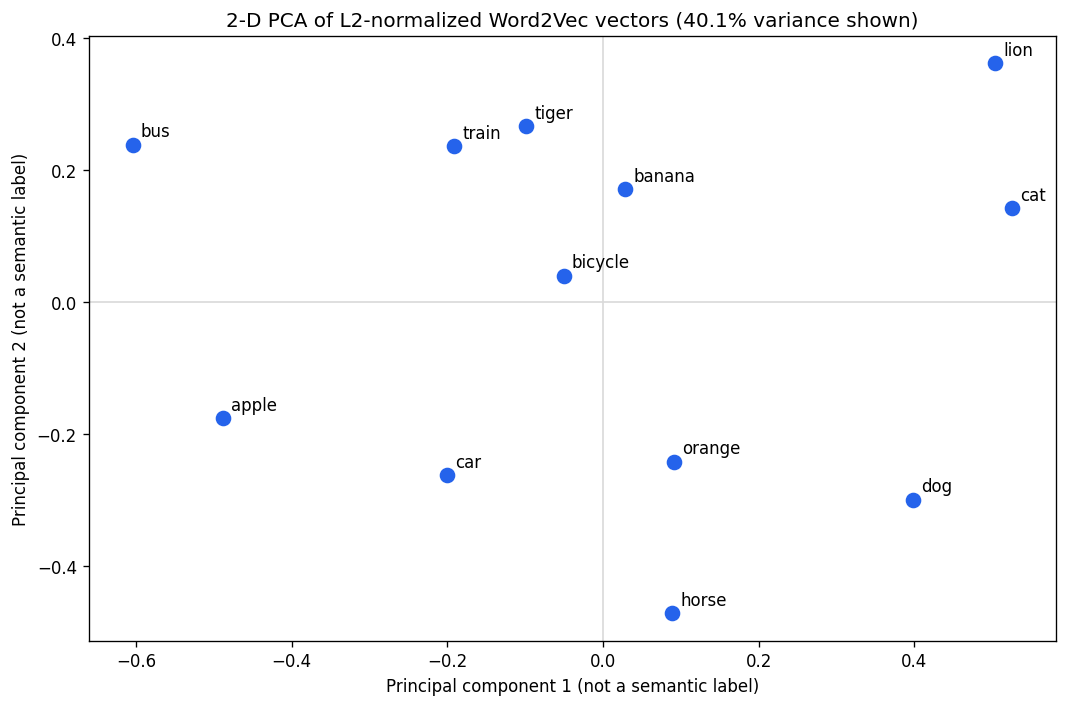

Saved PCA plot to: /content/word2vec_outputs/pca_words.png
Reminder: distances here can differ from relationships in the original 100-D space.


In [ ]:
# ===== CELL 10: A 2-D MAP OF THE WORDS (PCA) =====
# SUMMARY: Grab the real 100-number vectors for our WORDS list, skip any OOV words,
# make every vector length 1, squash 100 dimensions down to 2 with PCA, and draw
# a labeled scatter plot. Saved as word2vec_outputs/pca_words.png.

plot_words = [word.lower().strip() for word in WORDS]                                 # tidy every word
available_words = [word for word in plot_words if word in model.wv.key_to_index]      # words WITH an address
missing_words = [word for word in plot_words if word not in model.wv.key_to_index]    # OOV words

if missing_words:
    print("OOV words omitted from both plots:", missing_words)       # report, don't crash
if len(available_words) < 2:
    raise ValueError("Choose at least two in-vocabulary WORDS for PCA and a heatmap.")  # can't compare fewer than 2

# Stack real 100-D Word2Vec vectors, one row per retained requested word.
original_vectors = np.vstack([model.wv[word] for word in available_words])  # vstack = "vertical stack": one row per word
l2_norms = np.linalg.norm(original_vectors, axis=1, keepdims=True)          # each row's length; keepdims keeps a column shape
normalized_vectors = original_vectors / l2_norms                            # divide -> every vector has length 1 (L2 normalization)

pca = PCA(n_components=2, random_state=SEED)                # keep the 2 directions with the most spread
coordinates = pca.fit_transform(normalized_vectors)         # fit = find those directions; transform = project onto them
variance_shown = 100 * pca.explained_variance_ratio_.sum()  # % of the total spread that survived the flattening

fig, ax = plt.subplots(figsize=(9, 6))                                       # a blank 9x6-inch canvas
ax.scatter(coordinates[:, 0], coordinates[:, 1], s=70, color="#2563eb")      # one dot per word (x = column 0, y = column 1)
for word, (x_value, y_value) in zip(available_words, coordinates):           # zip pairs each word with its (x, y)
    ax.annotate(word, (x_value, y_value), xytext=(5, 5), textcoords="offset points")  # label 5 points up-right of the dot
ax.axhline(0, color="0.85", linewidth=1)    # light-gray horizontal center line
ax.axvline(0, color="0.85", linewidth=1)    # light-gray vertical center line
ax.set_title(f"2-D PCA of L2-normalized Word2Vec vectors ({variance_shown:.1f}% variance shown)")
ax.set_xlabel("Principal component 1 (not a semantic label)")
ax.set_ylabel("Principal component 2 (not a semantic label)")
fig.tight_layout()                          # tidy the spacing

pca_path = OUTPUT_DIR / "pca_words.png"                 # "/" joins folder and file name with Path
fig.savefig(pca_path, dpi=160, bbox_inches="tight")     # save the image file
plt.show()                                              # display it in the notebook
print(f"Saved PCA plot to: {pca_path.resolve()}")
print("Reminder: distances here can differ from relationships in the original 100-D space.")

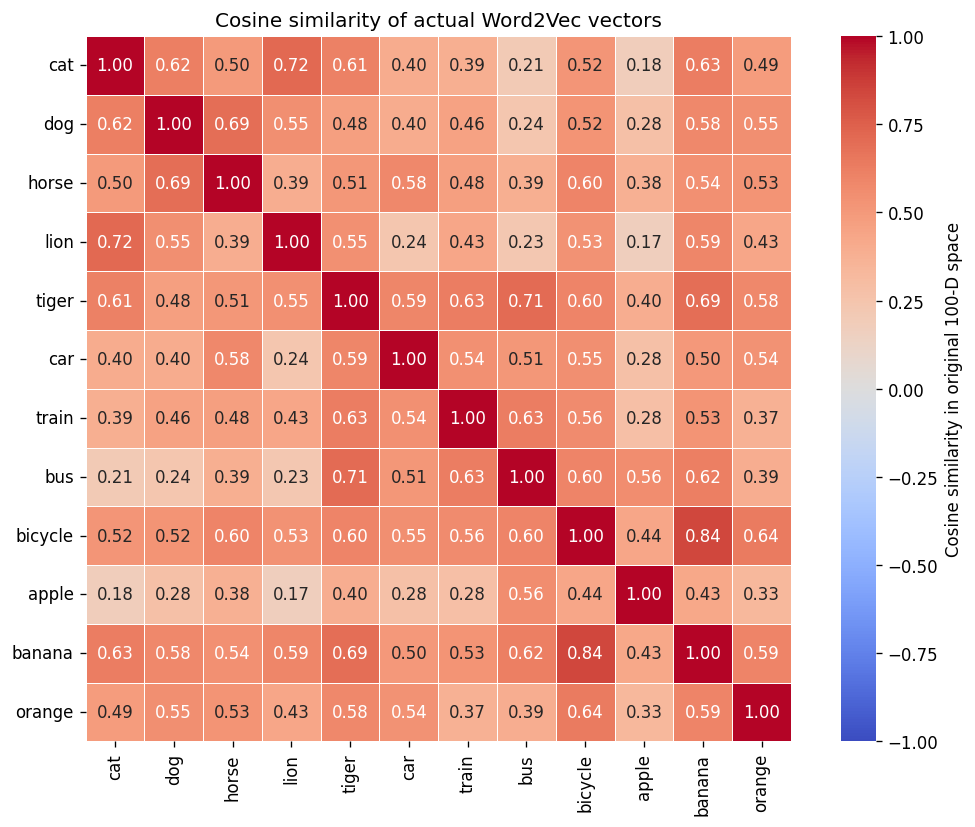

Saved heatmap to: /content/word2vec_outputs/cosine_heatmap.png


In [ ]:
# ===== CELL 11: THE COSINE HEATMAP (IN THE FULL 100 DIMENSIONS) =====
# SUMMARY: Compare every plotted word with every other word using cosine similarity in
# the ORIGINAL 100-D space (no flattening), and color the scores as a heatmap.
# Saved as word2vec_outputs/cosine_heatmap.png.

# cosine_similarity on normalized vectors produces every requested word pair.
# This matrix is calculated in the original 100-D vector space, not the PCA plane.
similarity_matrix = cosine_similarity(normalized_vectors)   # one table in -> a square table: every row vs. every row

fig, ax = plt.subplots(figsize=(9, 7))      # a blank 9x7-inch canvas
sns.heatmap(
    similarity_matrix,                  # the 12x12 table of scores
    xticklabels=available_words,        # word names along the bottom
    yticklabels=available_words,        # word names down the side
    annot=True,                         # write the number inside every box
    fmt=".2f",                          # ...with 2 decimals
    vmin=-1,                            # color scale starts at cosine's minimum
    vmax=1,                             # ...and ends at its maximum
    cmap="coolwarm",                    # blue = low, red = high
    square=True,                        # square boxes
    linewidths=0.4,                     # thin white lines between boxes
    cbar_kws={"label": "Cosine similarity in original 100-D space"},  # label for the color bar
    ax=ax,                              # draw on our canvas
)
ax.set_title("Cosine similarity of actual Word2Vec vectors")
fig.tight_layout()

heatmap_path = OUTPUT_DIR / "cosine_heatmap.png"
fig.savefig(heatmap_path, dpi=160, bbox_inches="tight")    # save the image file
plt.show()                                                 # display it
print(f"Saved heatmap to: {heatmap_path.resolve()}")

In [ ]:
# ===== BONUS CELL B (not in the original notebook): THE DETECTIVE CELL =====
# SUMMARY: For each suspicious word, print how many times it appeared in our training
# text and its 3 nearest neighbors. Rare words and surprising neighbors explain the map.

for word in ["cat", "dog", "lion", "tiger", "bicycle", "banana", "apple", "orange", "king"]:
    if word in model.wv.key_to_index:                         # only words that have an address
        count = model.wv.get_vecattr(word, "count")           # how many times it appeared in the 2,000,000 words
        top3 = [w for w, _ in model.wv.most_similar(word, topn=3)]   # just the neighbor words, not the scores
        print(f"{word:>8s}  appears {count:>5,} times   neighbors: {top3}")
    else:
        print(f"{word:>8s}  is out of vocabulary")

     cat  appears    55 times   neighbors: ['sadler', 'herb', 'donnell']
     dog  appears    86 times   neighbors: ['haired', 'stray', 'eat']
    lion  appears    69 times   neighbors: ['perseus', 'wardrobe', 'witch']
   tiger  appears    33 times   neighbors: ['crouching', 'falcon', 'gt']
 bicycle  appears    18 times   neighbors: ['slowing', 'fragmentation', 'elastic']
  banana  appears    10 times   neighbors: ['hexadecimal', 'lengthened', 'inline']
   apple  appears   707 times   neighbors: ['macintosh', 'iic', 'atari']
  orange  appears    83 times   neighbors: ['anzac', 'hiroshima', 'astro']
    king  appears 1,096 times   neighbors: ['macedon', 'iv', 'aragon']


In [ ]:
# =====================================================================================
#  BUILD YOUR OWN WORD2VEC: A STEP-BY-STEP TEMPLATE (works with any text)
# =====================================================================================
#  HOW TO USE THIS CELL
#   1. Paste this whole cell into Google Colab.
#   2. In STEP 1, pick a dataset (or use your own file).
#   3. Work down the steps. Every line marked  # TODO  is yours to fill in.
#      Anything left as None gets skipped with a "TODO" message instead of crashing.
#   4. Re-run the cell after each step you finish. Read every printed output.
#
#  THE BIG IDEA: "You shall know a word by the company it keeps."
#  Word2Vec reads lots of text and gives every word an "address" (a list of numbers).
#  Words that appear in similar company end up with similar addresses.
# =====================================================================================

# ---------- STEP 0: INSTALL AND IMPORT (already done for you) ------------------------
%pip -q install -U "gensim>=4.3" "scikit-learn>=1.3" "matplotlib>=3.7" "seaborn>=0.13" nltk

import re
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import nltk
import gensim.downloader as api
from gensim.models import Word2Vec
from gensim.models.word2vec import Text8Corpus
from gensim.utils import simple_preprocess          # lowercases, strips punctuation, splits into words
from sklearn.decomposition import PCA
from sklearn.metrics.pairwise import cosine_similarity

SEED = 42
np.random.seed(SEED)


# ---------- STEP 1: CHOOSE YOUR DATASET ----------------------------------------------
#  Pick ONE name and put it in DATASET below.
#
#   "brown"        ~1.0M words  | 500 texts of 1960s American English: news, fiction, science, humor
#   "gutenberg"    ~2.1M words  | 18 classic books (Austen, Shakespeare, the Bible, Moby Dick...)
#   "reuters"      ~1.3M words  | 10,000+ business and financial news stories
#   "movie_reviews"~1.3M words  | 2,000 movie reviews (positive and negative)
#   "newsgroups"                | 18,000 online forum posts on 20 topics (space, cars, religion, hockey...)
#   "text8"        2M words     | Wikipedia, the dataset from class (capped at MAX_TOKENS)
#   "my_file"                   | YOUR OWN .txt file: upload it in Colab's Files panel (left sidebar)
#   You can also go to: https://www.gutenberg.org and download a book and use that
#.  i.e.: for pride and prejudice: !wget -q -O my_text.txt https://www.gutenberg.org/cache/epub/1342/pg1342.txt
#  Tip: a word needs to appear at least MIN_COUNT times to get an address.
#  Choose words to explore that actually show up in YOUR dataset (a hockey word won't be in Austen).

DATASET = "brown"                 # TODO: change this to the dataset you picked
MY_FILE = "my_text.txt"           # only used if DATASET = "my_file"
MAX_TOKENS = 2_000_000            # cap for big datasets (text8 and my_file)


# ---------- STEP 2: LOAD THE TEXT AS A LIST OF SENTENCES (done for you) --------------
#  Word2Vec needs a LIST OF LISTS: each inner list is one sentence, already split into
#  lowercase words. Example: [["the", "cat", "sat"], ["a", "dog", "ran"]]

def clean(words):
    """Lowercase and keep only real words (letters only)."""
    return [w.lower() for w in words if re.fullmatch(r"[A-Za-z]+", w)]

def load_sentences(name):
    if name in ("brown", "gutenberg", "reuters", "movie_reviews"):
        nltk.download(name, quiet=True)
        nltk.download("punkt", quiet=True)
        nltk.download("punkt_tab", quiet=True)
        corpus = getattr(nltk.corpus, name)          # e.g. nltk.corpus.brown
        return [s for s in (clean(sent) for sent in corpus.sents()) if len(s) > 1]
    if name == "newsgroups":
        from sklearn.datasets import fetch_20newsgroups
        posts = fetch_20newsgroups(subset="all", remove=("headers", "footers", "quotes")).data
        return [s for s in (simple_preprocess(p) for p in posts) if len(s) > 1]
    if name == "text8":
        path = api.load("text8", return_path=True)   # the class fix: skip Gensim's broken loader
        sentences, kept = [], 0
        for chunk in Text8Corpus(path):
            sentences.append(chunk)
            kept += len(chunk)
            if kept >= MAX_TOKENS:
                break
        return sentences
    if name == "my_file":
        with open(MY_FILE, encoding="utf-8", errors="ignore") as f:
            lines = [simple_preprocess(line) for line in f]
        sentences, kept = [], 0
        for s in lines:
            if len(s) > 1:
                sentences.append(s)
                kept += len(s)
            if kept >= MAX_TOKENS:
                break
        return sentences
    raise ValueError(f"Unknown DATASET: {name}")

sentences = load_sentences(DATASET)

# TODO: print how many sentences you loaded, the total number of words,
#       and the first sentence, so you can SEE what Word2Vec will read.
#       Hint: len(sentences), sum(len(s) for s in sentences), sentences[0]



# ---------- STEP 3: CHOOSE YOUR SETTINGS ---------------------------------------------
#  These are the knobs. Write a comment next to each saying WHY you chose that value.

VECTOR_SIZE = None    # TODO: how many numbers per word? (class used 100)
WINDOW      = None    # TODO: how many words of context on each side? (class used 5)
MIN_COUNT   = None    # TODO: drop words seen fewer than this many times (class used 5)
SG          = None    # TODO: 1 = skip-gram, 0 = CBOW
NEGATIVE    = 5       # noise words per real pair (Gensim's default)
EPOCHS      = None    # TODO: how many passes through the text? (class used 5)


# ---------- STEP 4: TRAIN THE MODEL --------------------------------------------------
#  Build Word2Vec(...) using sentences= and every setting from STEP 3,
#  plus workers=1 and seed=SEED so your results are repeatable.

model = None          # TODO: model = Word2Vec(sentences=..., vector_size=..., ...)

if model is not None:
    print(f"Vocabulary size: {len(model.wv):,} words")
    print("Most frequent words:", model.wv.index_to_key[:10])
else:
    print("STEP 4 TODO: train your model.")


# ---------- STEP 5: SAVE YOUR GAME ---------------------------------------------------
MODEL_PATH = f"word2vec_{DATASET}.model"
if model is not None:
    pass              # TODO: save the model to MODEL_PATH, then load it back into model
                      # Hint: model.save(...) and Word2Vec.load(...)


# ---------- STEP 6: WHO LIVES NEAR? (nearest neighbors) ------------------------------
#  Pick 3 words that matter in YOUR dataset (check they're in the vocabulary first).

MY_WORDS = []         # TODO: e.g. ["money", "god", "love"]  -> choose words from YOUR dataset

def in_vocab(word):
    ok = model is not None and word in model.wv.key_to_index
    if model is not None and not ok:
        print(f"'{word}' is out of vocabulary (OOV). Try a more common word.")
    return ok

for word in MY_WORDS:
    if in_vocab(word):
        pass          # TODO: print the 5 nearest neighbors of word
                      # Hint: model.wv.most_similar(word, topn=5)


# ---------- STEP 7: MEASURE ONE PAIR (cosine similarity) -----------------------------
PAIR = (None, None)   # TODO: two words you think are related, e.g. ("man", "woman")

if all(PAIR) and all(in_vocab(w) for w in PAIR):
    pass              # TODO: print the cosine similarity between the two words
                      # Hint: model.wv.similarity(PAIR[0], PAIR[1])


# ---------- STEP 8: THE ANALOGY PROBE (B - A + C) ------------------------------------
A, B, C = None, None, None   # TODO: e.g. A="man", B="king", C="woman"  ->  king - man + woman

if all([A, B, C]) and all(in_vocab(w) for w in [A, B, C]):
    pass              # TODO: print the top 5 results
                      # Hint: model.wv.most_similar(positive=[B, C], negative=[A], topn=5)


# ---------- STEP 9: DRAW THE MAP (PCA scatter + cosine heatmap) ----------------------
#  Choose 8-15 words in 2-3 "teams" you expect to cluster (e.g. 4 places, 4 people, 4 foods).

PLOT_WORDS = []       # TODO: your list of words

plot_words = [w for w in PLOT_WORDS if in_vocab(w)]
if len(plot_words) >= 2:
    vectors = np.vstack([model.wv[w] for w in plot_words])
    vectors = vectors / np.linalg.norm(vectors, axis=1, keepdims=True)   # length 1: only direction counts

    # TODO: run PCA with n_components=2 on vectors and get 2-D coordinates
    coords = None     # Hint: PCA(n_components=2, random_state=SEED).fit_transform(vectors)

    if coords is not None:
        plt.figure(figsize=(8, 6))
        plt.scatter(coords[:, 0], coords[:, 1])
        for w, (x, y) in zip(plot_words, coords):
            plt.annotate(w, (x, y), xytext=(5, 5), textcoords="offset points")
        plt.title(f"2-D PCA of Word2Vec vectors ({DATASET})")
        plt.show()

    # TODO: compute the cosine similarity table for vectors, then draw it with sns.heatmap
    sim = None        # Hint: cosine_similarity(vectors)
    if sim is not None:
        plt.figure(figsize=(8, 7))
        sns.heatmap(sim, xticklabels=plot_words, yticklabels=plot_words,
                    annot=True, fmt=".2f", vmin=-1, vmax=1, cmap="coolwarm", square=True)
        plt.title(f"Cosine similarity ({DATASET})")
        plt.show()


# ---------- STEP 10: PLAY DETECTIVE --------------------------------------------------
#  For any word that surprised you, check how often it appeared and who its neighbors are.

SUSPECTS = []         # TODO: words whose results surprised you
for w in SUSPECTS:
    if in_vocab(w):
        pass          # TODO: print the word, its count, and its 3 nearest neighbors
                      # Hint: model.wv.get_vecattr(w, "count")


# ---------- STEP 11: REFLECT (answer in a text cell below) ---------------------------
#  1. Which neighbor or score surprised you most, and what in the TEXT explains it?
#  2. Did your "teams" cluster on the heatmap? Did the PCA plot tell the same story?
#  3. Which words were rare, and how did that affect their neighbors?
#  4. Change ONE setting (SG, EPOCHS, WINDOW, or the dataset), retrain, and describe what changed.

STEP 4 TODO: train your model.


## 5 Practical Things You Can Build With Word2Vec

**1. Smart Search Expander**
Train on product reviews or a store catalog. When someone searches "cheap," also search its nearest neighbors ("affordable," "inexpensive," "budget"), so a search still finds products that use different words.
*Uses:* `most_similar`

**2. Author Style Detective**
Train one model on Jane Austen and another on Arthur Conan Doyle (both free on Project Gutenberg). Compare the neighbors of the same words, like "love," "money," and "fear," to see how each author uses them differently.
*Uses:* training on your own file, `most_similar`, comparing two models

**3. Customer Complaint Finder**
Train on support tickets or airline reviews. Start with the word "refund" and find its neighbors to discover the other words customers use when they're unhappy, then flag reviews that contain them.
*Uses:* `most_similar`, `similarity`

**4. "Odd One Out" Game**
Give the model a list like ["apple", "banana", "orange", "car"] and have it find the word that doesn't fit. That's the word with the lowest average cosine similarity to the others. Turn it into a quiz with a score.
*Uses:* `cosine_similarity`, the heatmap

**5. Topic Map of News**
Train on Reuters news, pick 15 words from three industries (oil, banking, farming), and draw the PCA map and heatmap. Do the industries form their own neighborhoods? Write up what the map shows a business analyst.
*Uses:* PCA, `sns.heatmap`, the detective cell